# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The Agent Pagination Dataset](https://www.kaggle.com/datasets/muzammalhussain11/agent-pagination-integrity-benchmark?select=per_episode_results.csv)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('per_episode_results.csv')

# Preprocessing

## Frist five row

In [3]:
df.head()

,episode_id,seed,scenario,policy,expected_total,unique_retrieved,raw_items_returned,coverage,calls,reported_complete,actual_complete,false_completion,incomplete_detected,termination
0,s17_e0000,17,stable,first_page_only,29,6,6,0.206897,1,1,0,1,0,agent_stopped_after_first_page
1,s17_e0000,17,stable,stop_on_empty,29,29,29,1.000000,5,1,1,0,0,no_next_cursor
2,s17_e0000,17,stable,follow_cursor,29,29,29,1.000000,5,1,1,0,0,no_next_cursor
3,s17_e0000,17,stable,count_verified,29,29,29,1.000000,5,1,1,0,0,no_next_cursor
4,s17_e0001,17,empty_nonterminal,first_page_only,34,9,9,0.264706,1,1,0,1,0,agent_stopped_after_first_page


## last Five row

In [4]:
df.tail()

,episode_id,seed,scenario,policy,expected_total,unique_retrieved,raw_items_returned,coverage,calls,reported_complete,actual_complete,false_completion,incomplete_detected,termination
11995,s101_e0598,101,empty_nonterminal,count_verified,48,48,48,1.000000,11,1,1,0,0,no_next_cursor
11996,s101_e0599,101,duplicate_omission,first_page_only,30,7,7,0.233333,1,1,0,1,0,agent_stopped_after_first_page
11997,s101_e0599,101,duplicate_omission,stop_on_empty,30,29,30,0.966667,5,1,0,1,0,no_next_cursor
11998,s101_e0599,101,duplicate_omission,follow_cursor,30,29,30,0.966667,5,1,0,1,0,no_next_cursor
11999,s101_e0599,101,duplicate_omission,count_verified,30,29,30,0.966667,5,0,0,0,1,no_next_cursor


## Shape of our dataset

In [5]:
df.shape

(12000, 14)

## List out all columns

In [6]:
df.columns

Index(['episode_id', 'seed', 'scenario', 'policy', 'expected_total',
       'unique_retrieved', 'raw_items_returned', 'coverage', 'calls',
       'reported_complete', 'actual_complete', 'false_completion',
       'incomplete_detected', 'termination'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

episode_id              object
seed                     int64
scenario                object
policy                  object
expected_total           int64
unique_retrieved         int64
raw_items_returned       int64
coverage               float64
calls                    int64
reported_complete        int64
actual_complete          int64
false_completion         int64
incomplete_detected      int64
termination             object
dtype: object

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   episode_id           12000 non-null  object 
 1   seed                 12000 non-null  int64  
 2   scenario             12000 non-null  object 
 3   policy               12000 non-null  object 
 4   expected_total       12000 non-null  int64  
 5   unique_retrieved     12000 non-null  int64  
 6   raw_items_returned   12000 non-null  int64  
 7   coverage             12000 non-null  float64
 8   calls                12000 non-null  int64  
 9   reported_complete    12000 non-null  int64  
 10  actual_complete      12000 non-null  int64  
 11  false_completion     12000 non-null  int64  
 12  incomplete_detected  12000 non-null  int64  
 13  termination          12000 non-null  object 
dtypes: float64(1), int64(9), object(4)
memory usage: 1.3+ MB


## Check Null Value

In [9]:
df.isnull().sum()

episode_id             0
seed                   0
scenario               0
policy                 0
expected_total         0
unique_retrieved       0
raw_items_returned     0
coverage               0
calls                  0
reported_complete      0
actual_complete        0
false_completion       0
incomplete_detected    0
termination            0
dtype: int64

## Check Dupicate Value

In [10]:
df.duplicated().sum()

np.int64(0)

## Summary

In [11]:
df.describe()

,seed,expected_total,unique_retrieved,raw_items_returned,coverage,calls,reported_complete,actual_complete,false_completion,incomplete_detected
count,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000
mean,52.200000,41.664333,30.901833,31.046833,0.743050,4.408417,0.749750,0.396167,0.502333,0.101500
std,30.322213,10.797965,16.764017,16.853426,0.333279,2.747042,0.433175,0.489120,0.500015,0.302002
min,17.000000,24.000000,5.000000,5.000000,0.083333,1.000000,0.000000,0.000000,0.000000,0.000000
25%,29.000000,32.000000,12.000000,12.000000,0.375000,1.750000,0.000000,0.000000,0.000000,0.000000
50%,43.000000,41.000000,32.000000,32.000000,0.970588,4.000000,1.000000,0.000000,1.000000,0.000000
75%,71.000000,51.000000,45.000000,45.000000,1.000000,6.000000,1.000000,1.000000,1.000000,0.000000
max,101.000000,60.000000,60.000000,60.000000,1.000000,13.000000,1.000000,1.000000,1.000000,1.000000


# EDA

In [12]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

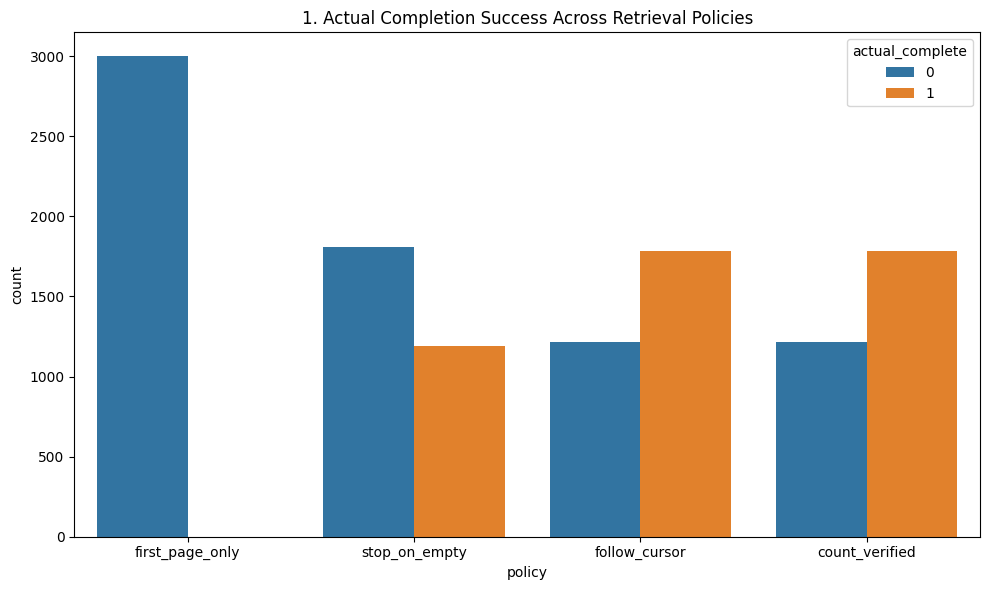

In [13]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='policy', hue='actual_complete')
plt.title(f'{plot_no}. Actual Completion Success Across Retrieval Policies')
show_fig()
plot_no += 1

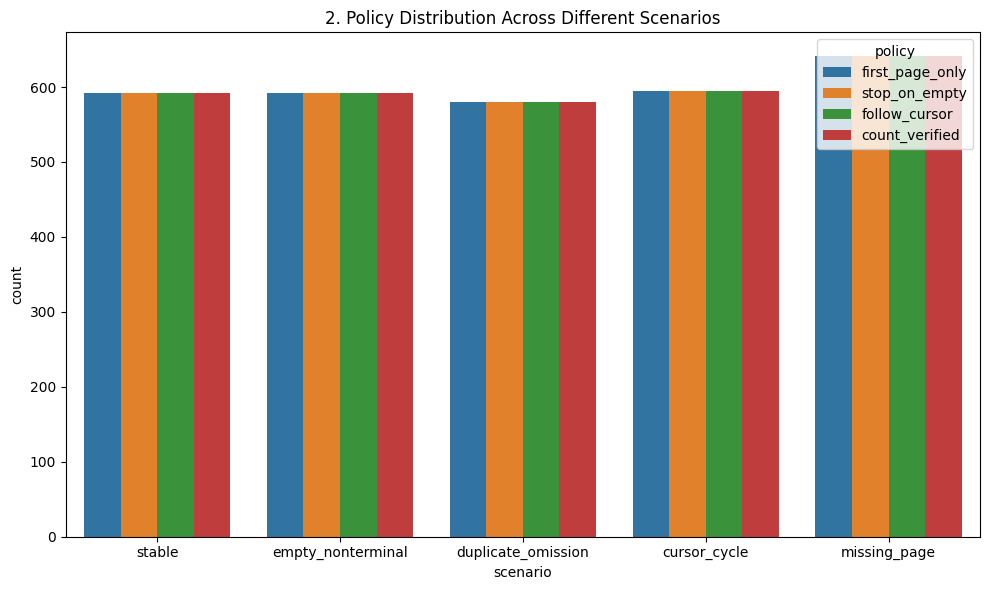

In [14]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='scenario', hue='policy')
plt.title(f'{plot_no}. Policy Distribution Across Different Scenarios')
show_fig()
plot_no += 1

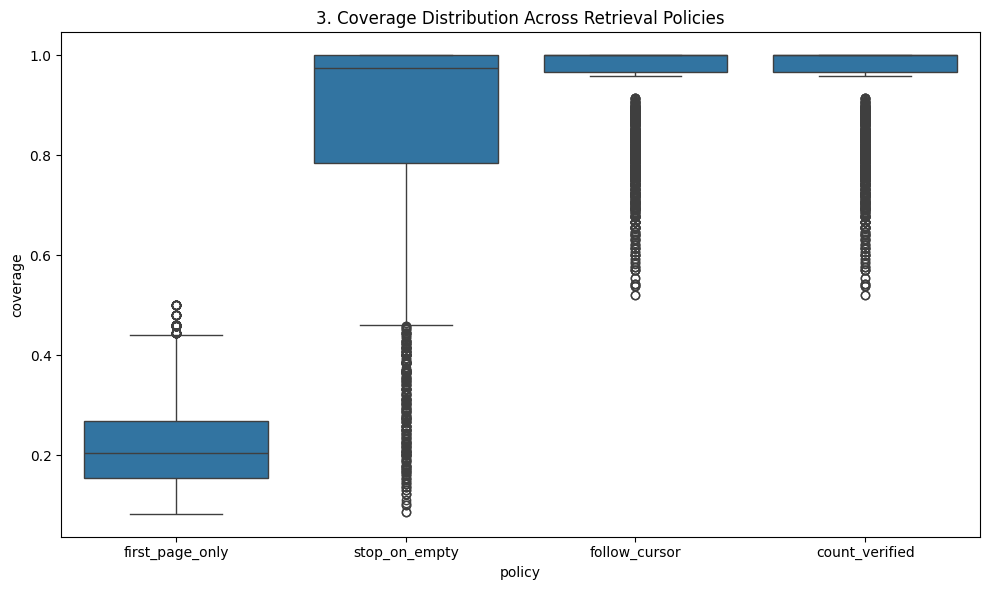

In [15]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='policy', y='coverage')
plt.title(f'{plot_no}. Coverage Distribution Across Retrieval Policies')
show_fig()
plot_no += 1

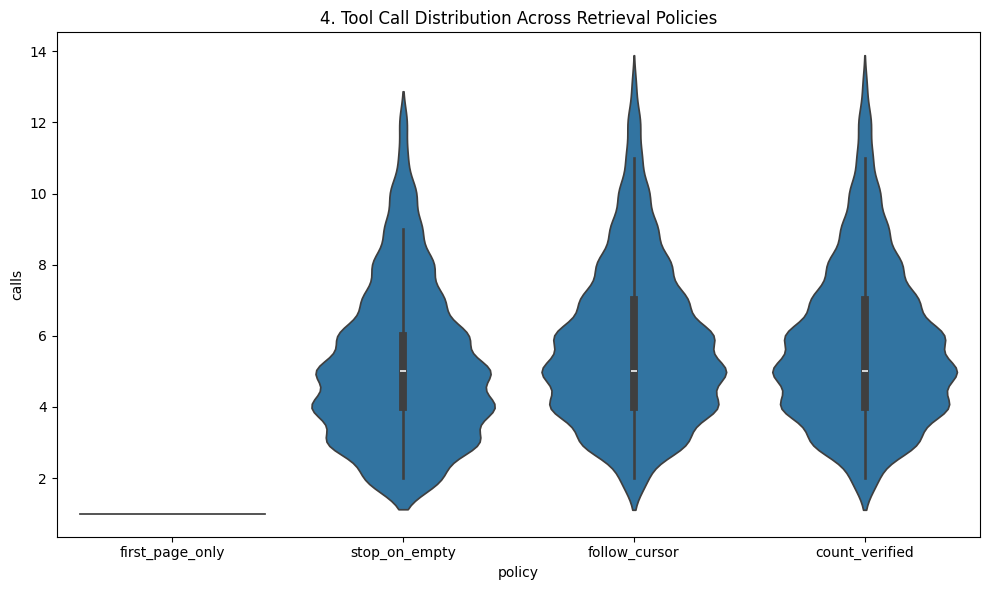

In [16]:
fig = plt.figure(figsize=(10,6))
sns.violinplot(data=df, x='policy', y='calls')
plt.title(f'{plot_no}. Tool Call Distribution Across Retrieval Policies')
show_fig()
plot_no += 1

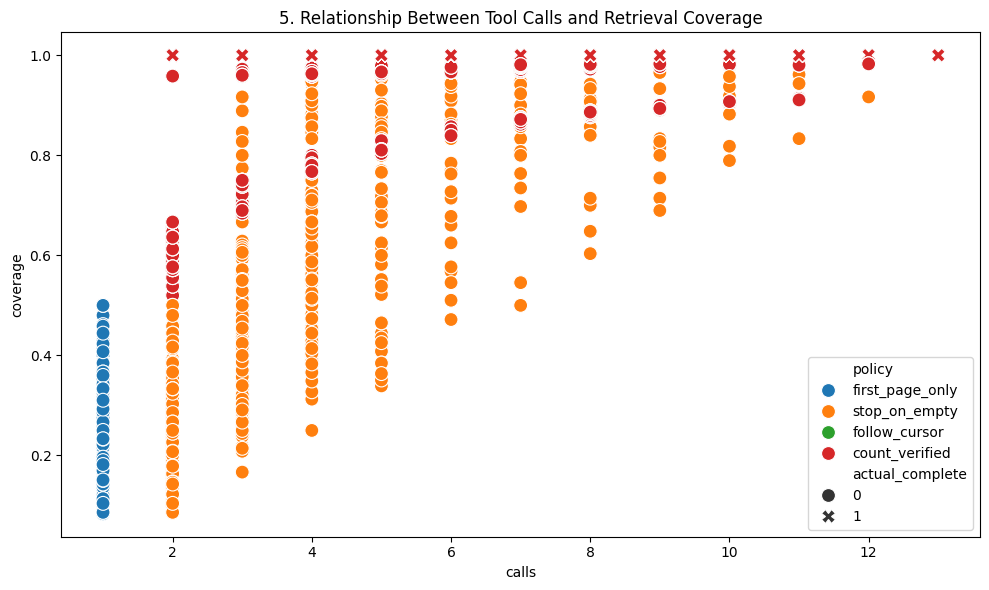

In [17]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='calls', y='coverage', hue='policy', style='actual_complete', s=100)
plt.title(f'{plot_no}. Relationship Between Tool Calls and Retrieval Coverage')
show_fig()
plot_no += 1

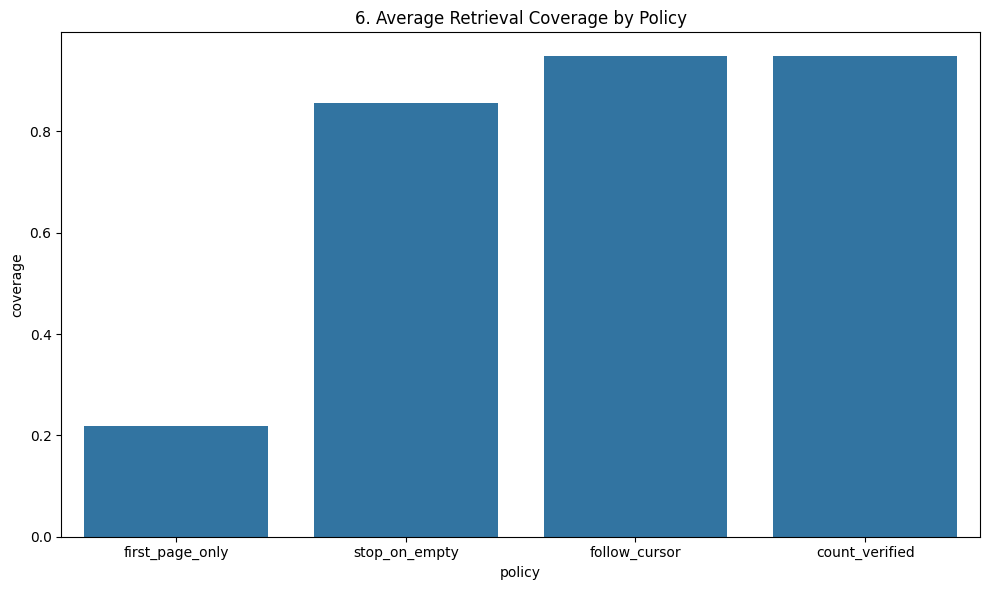

In [18]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='policy', y='coverage', errorbar=None)
plt.title(f'{plot_no}. Average Retrieval Coverage by Policy')
show_fig()
plot_no += 1

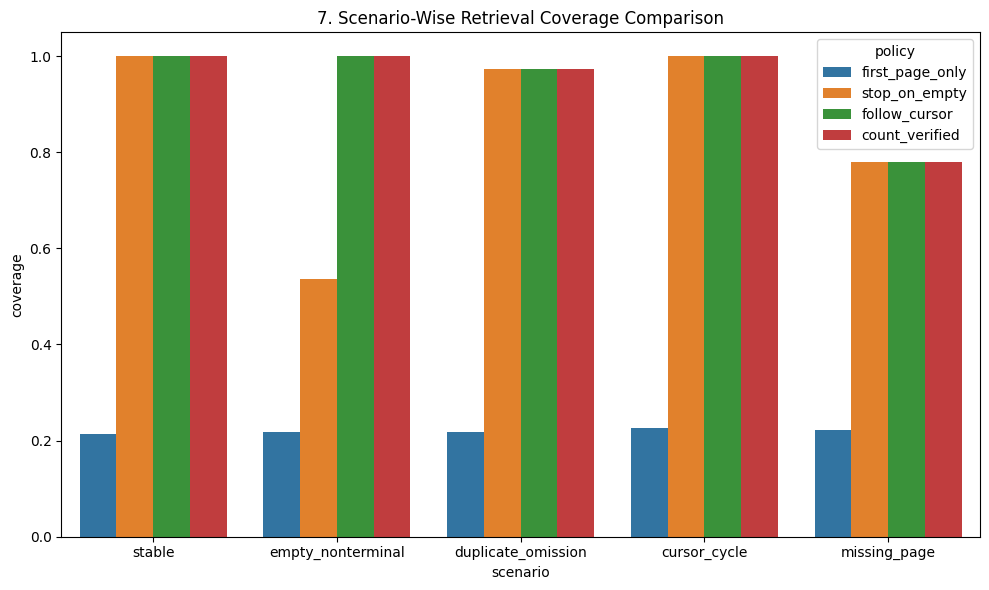

In [19]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='scenario', y='coverage', hue='policy', errorbar=None)
plt.title(f'{plot_no}. Scenario-Wise Retrieval Coverage Comparison')
show_fig()
plot_no += 1

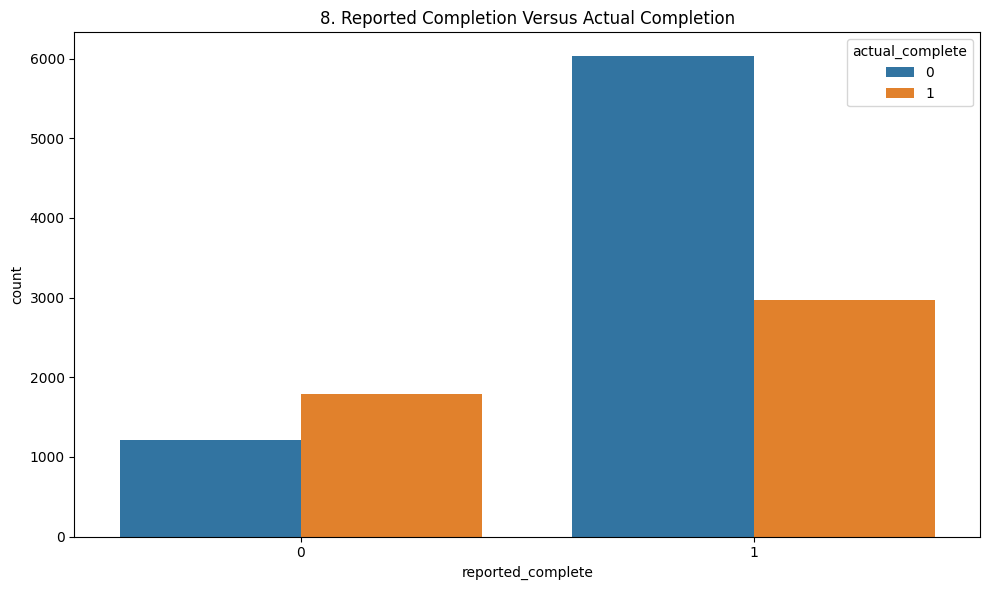

In [20]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='reported_complete', hue='actual_complete')
plt.title(f'{plot_no}. Reported Completion Versus Actual Completion')
show_fig()
plot_no += 1

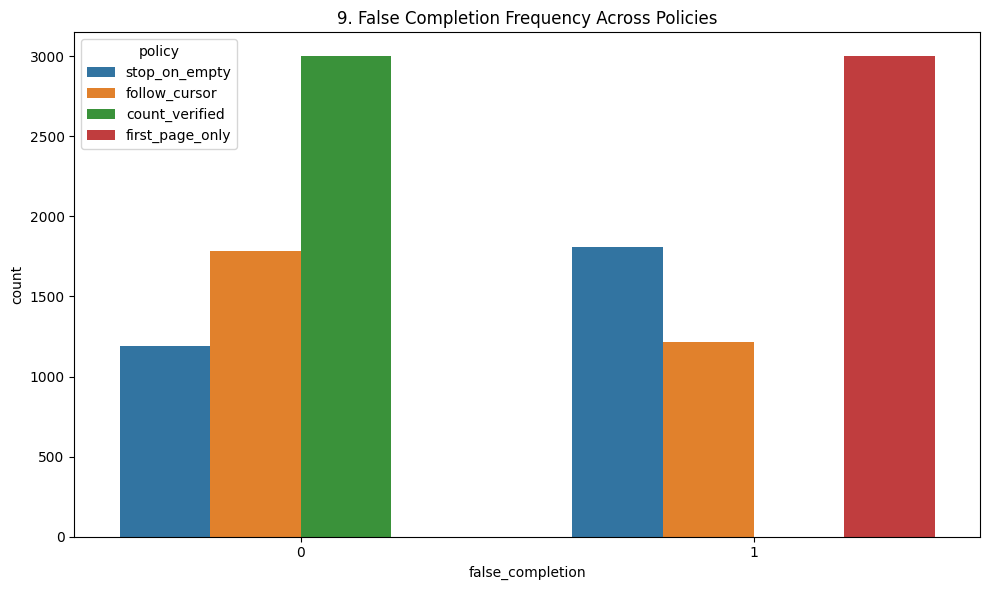

In [21]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='false_completion', hue='policy')
plt.title(f'{plot_no}. False Completion Frequency Across Policies')
show_fig()
plot_no += 1

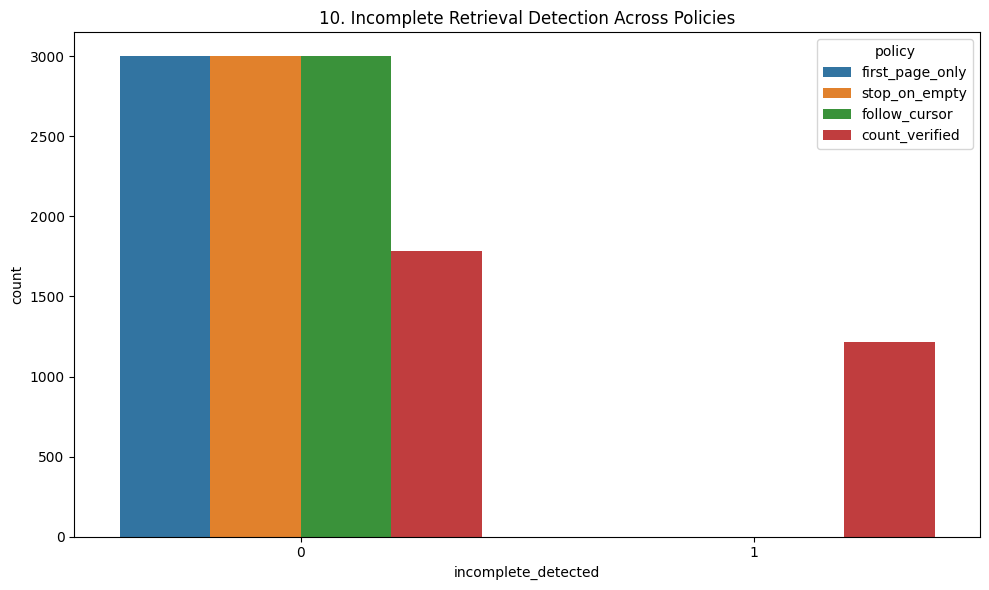

In [22]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='incomplete_detected', hue='policy')
plt.title(f'{plot_no}. Incomplete Retrieval Detection Across Policies')
show_fig()
plot_no += 1

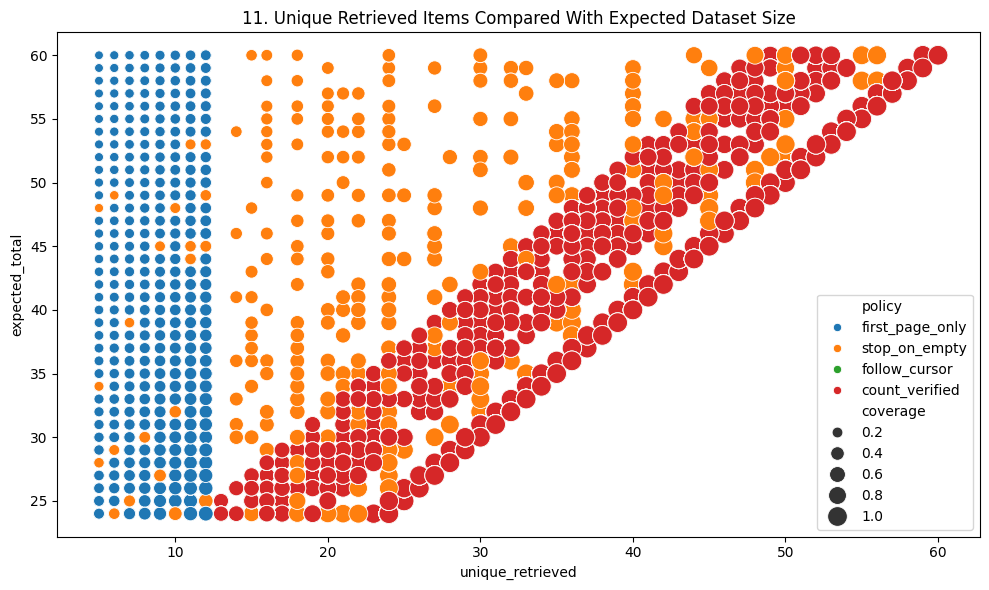

In [23]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='unique_retrieved', y='expected_total', hue='policy', size='coverage', sizes=(40,200))
plt.title(f'{plot_no}. Unique Retrieved Items Compared With Expected Dataset Size')
show_fig()
plot_no += 1

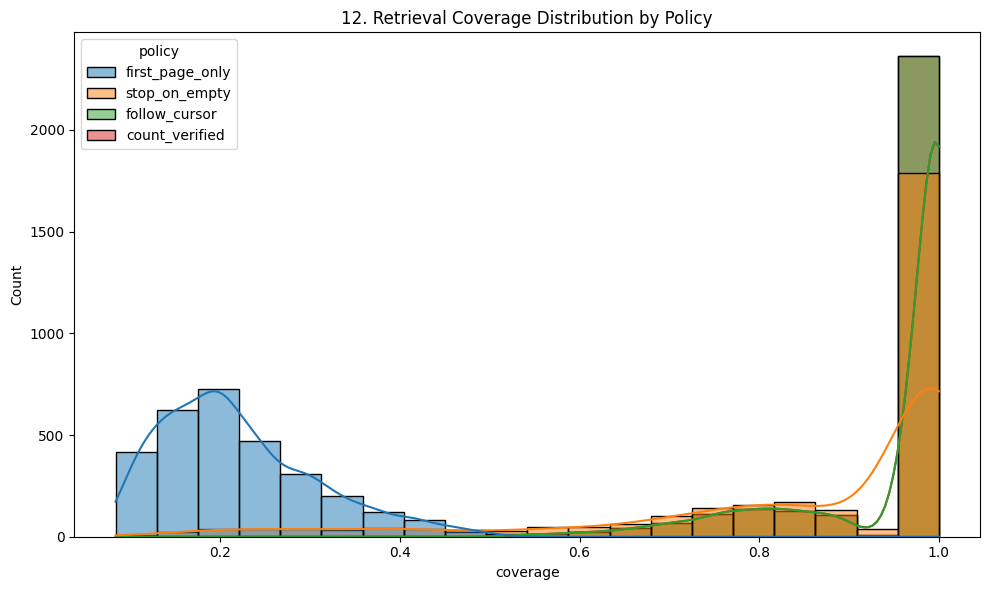

In [24]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='coverage', hue='policy', kde=True, bins=20, multiple='layer')
plt.title(f'{plot_no}. Retrieval Coverage Distribution by Policy')
show_fig()
plot_no += 1

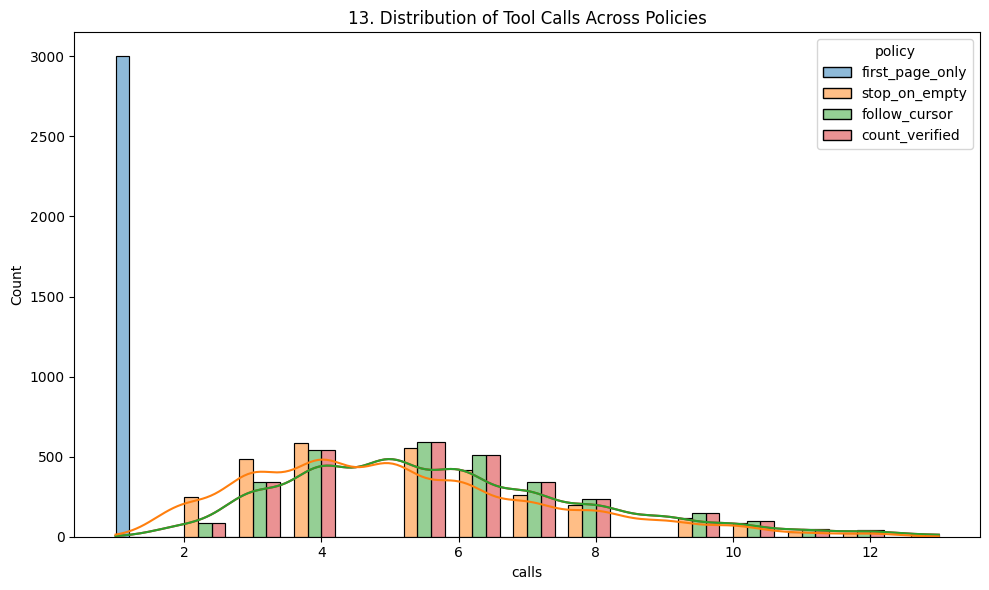

In [25]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='calls', hue='policy', kde=True, bins=15, multiple='dodge')
plt.title(f'{plot_no}. Distribution of Tool Calls Across Policies')
show_fig()
plot_no += 1

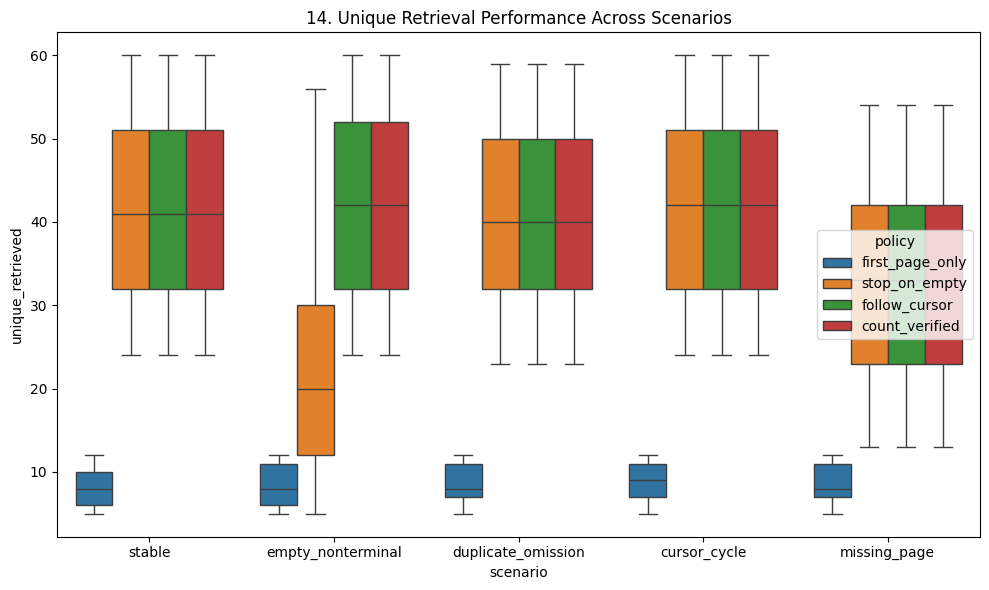

In [26]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='scenario', y='unique_retrieved', hue='policy')
plt.title(f'{plot_no}. Unique Retrieval Performance Across Scenarios')
show_fig()
plot_no += 1

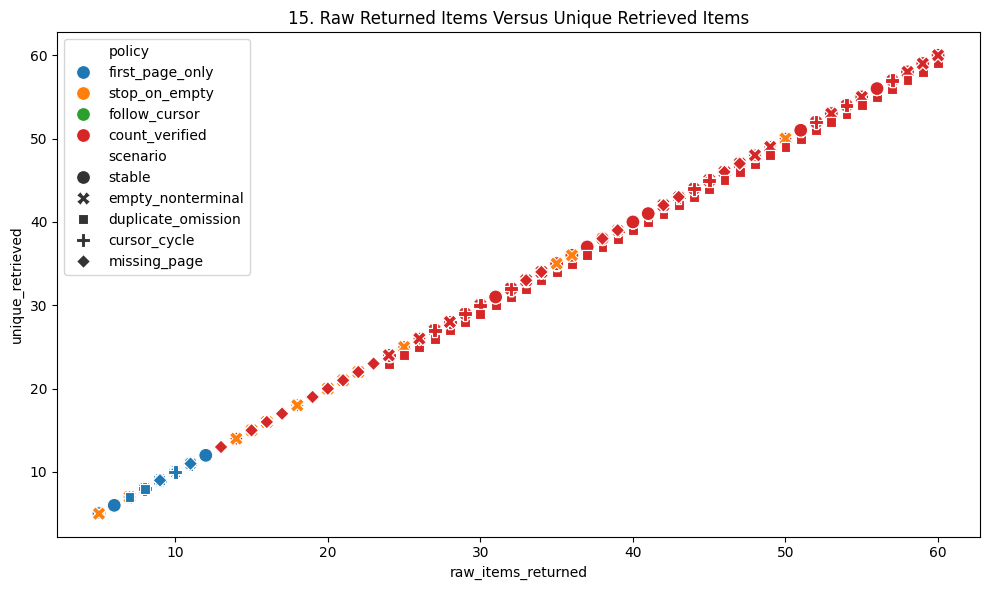

In [27]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='raw_items_returned', y='unique_retrieved', hue='policy', style='scenario', s=100)
plt.title(f'{plot_no}. Raw Returned Items Versus Unique Retrieved Items')
show_fig()
plot_no += 1

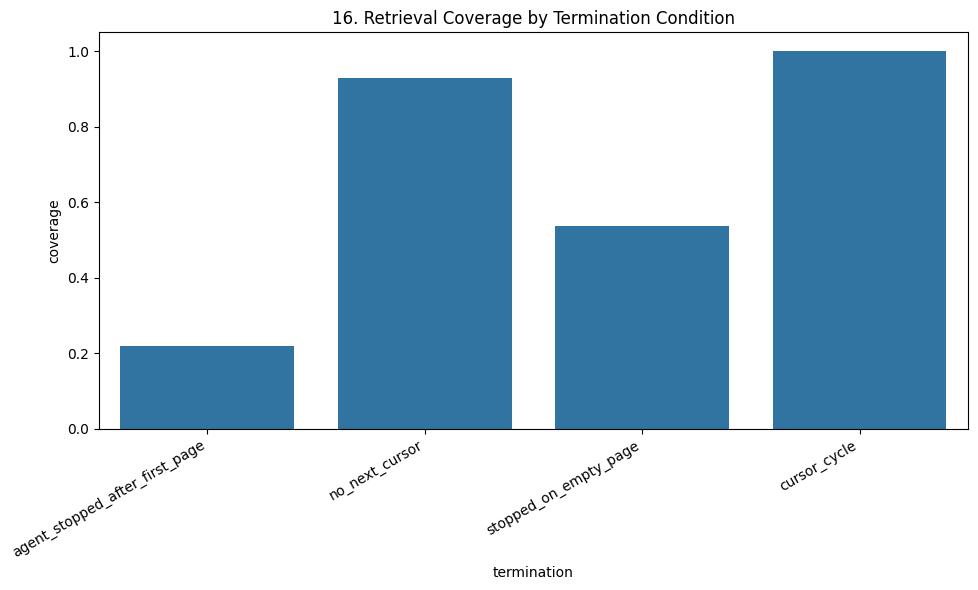

In [28]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='termination', y='coverage', errorbar=None)
plt.xticks(rotation=30, ha='right')
plt.title(f'{plot_no}. Retrieval Coverage by Termination Condition')
show_fig()
plot_no += 1

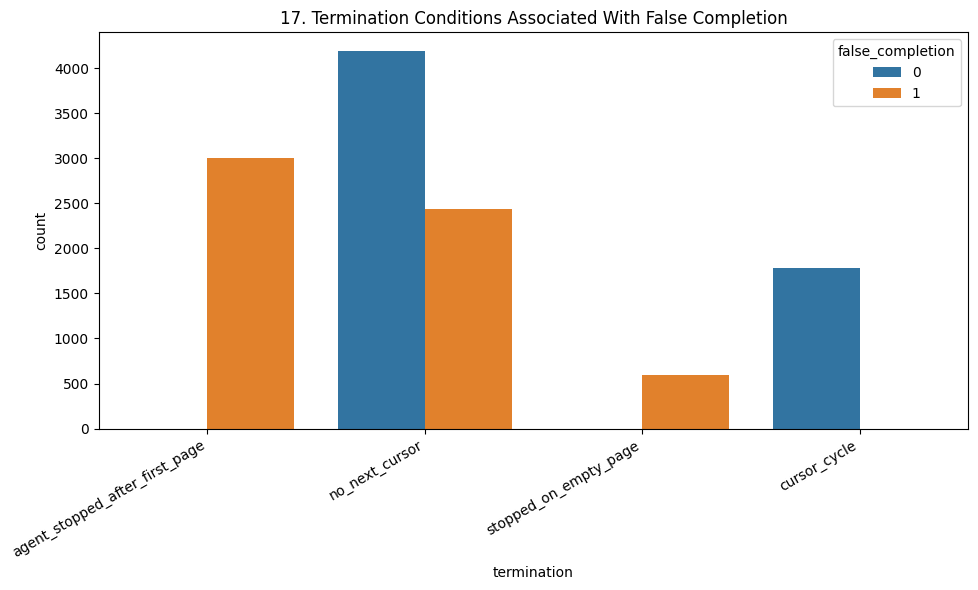

In [29]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='termination', hue='false_completion')
plt.xticks(rotation=30, ha='right')
plt.title(f'{plot_no}. Termination Conditions Associated With False Completion')
show_fig()
plot_no += 1

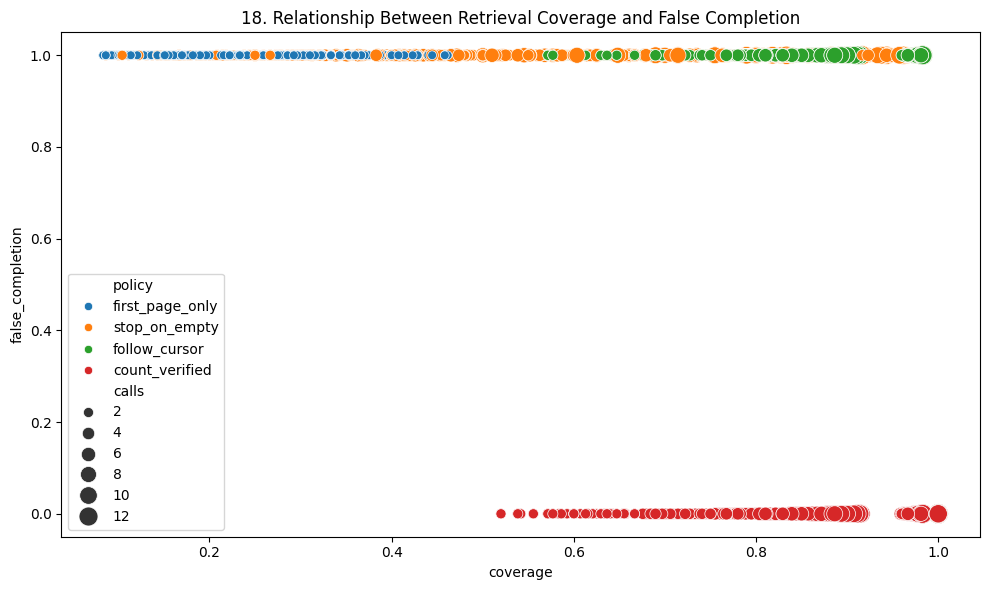

In [30]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='coverage', y='false_completion', hue='policy', size='calls', sizes=(40,200))
plt.title(f'{plot_no}. Relationship Between Retrieval Coverage and False Completion')
show_fig()
plot_no += 1

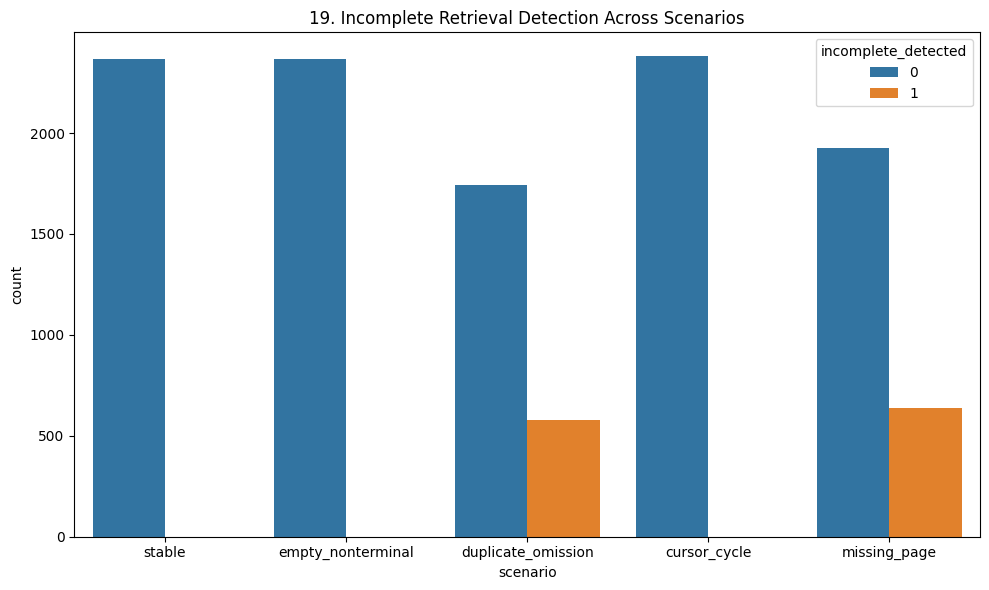

In [31]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='scenario', hue='incomplete_detected')
plt.title(f'{plot_no}. Incomplete Retrieval Detection Across Scenarios')
show_fig()
plot_no += 1

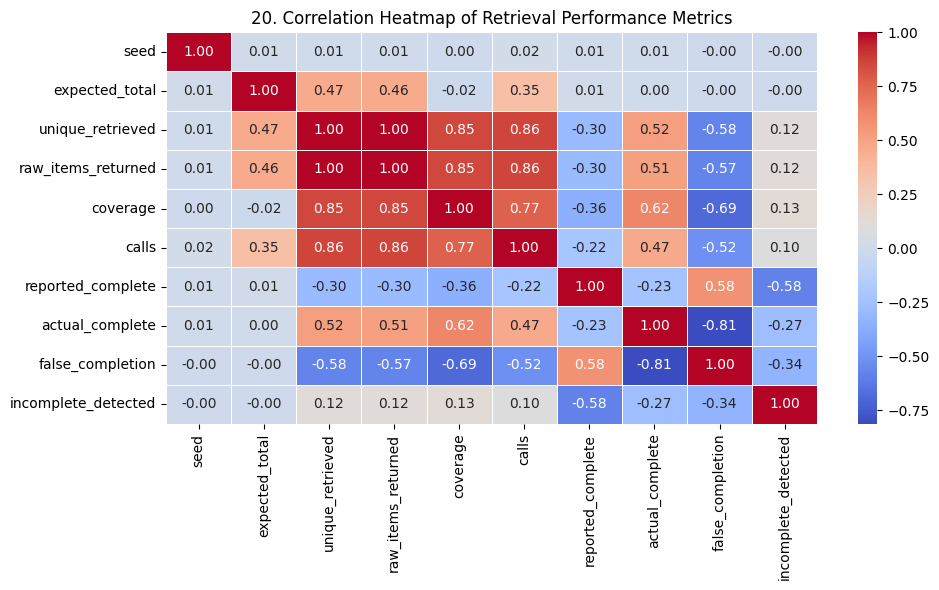

In [32]:
fig = plt.figure(figsize=(10,6))
corr = df.select_dtypes(include='number').corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title(f'{plot_no}. Correlation Heatmap of Retrieval Performance Metrics')
show_fig()
plot_no += 1

# Model Training

## Prepare dataset

In [33]:
data = df.copy()

data = data.drop(columns=['episode_id', 'seed', 'termination'], errors='ignore')

data = pd.get_dummies(data, drop_first=True)

data = data.replace([np.inf, -np.inf], np.nan)

data = data.dropna(subset=['coverage'])

X = data.drop(columns=['coverage'])
y = data['coverage']

X = X.fillna(X.median())

## Split dataset

In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Train model

In [35]:
model = HistGradientBoostingRegressor(
    max_iter=300,
    learning_rate=0.05,
    max_leaf_nodes=20,
    l2_regularization=1.0,
    random_state=42
)

model.fit(X_train, y_train)

,loss,'squared_error'
,quantile,None
,learning_rate,0.05
,max_iter,300
,max_leaf_nodes,20
,max_depth,None
,min_samples_leaf,20
,l2_regularization,1.0
,max_features,1.0
,max_bins,255
,categorical_features,'from_dtype'


## Make predictions

In [36]:
y_pred = model.predict(X_test)

## Evaluate model

In [37]:
print("R2 Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

print("Accuracy-like Score:", r2_score(y_test, y_pred) * 100, "%")

R2 Score: 0.999749932142627
MAE: 0.0019833946456526354
RMSE: 0.0052447507760060115
Accuracy-like Score: 99.9749932142627 %


## Actual vs Predicted

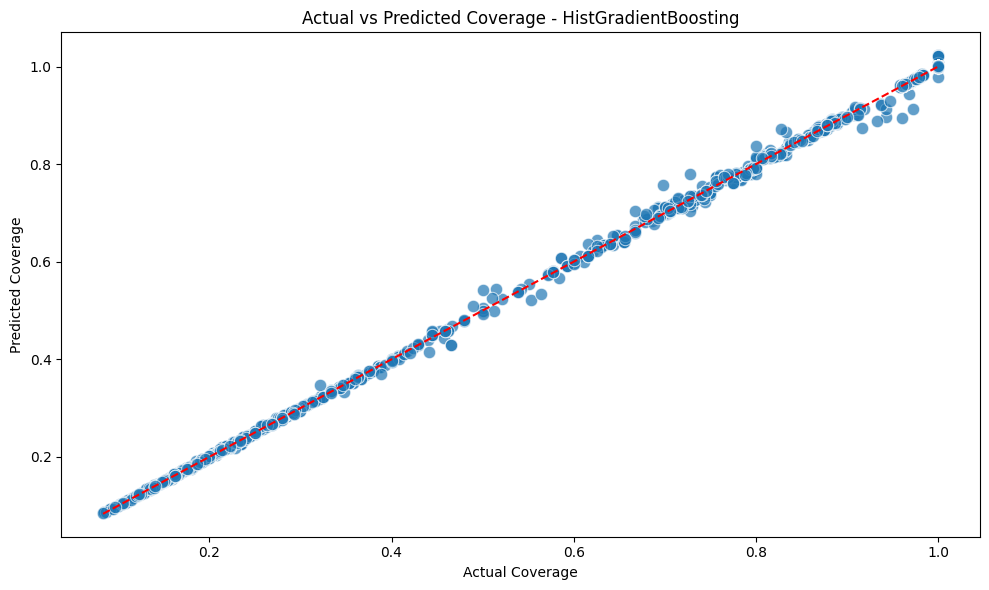

In [38]:
fig = plt.figure(figsize=(10,6))

sns.scatterplot(x=y_test, y=y_pred, alpha=0.7, s=80)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--',
    color='red'
)

plt.xlabel("Actual Coverage")
plt.ylabel("Predicted Coverage")
plt.title("Actual vs Predicted Coverage - HistGradientBoosting")

show_fig()